# Analisis Dataset Karyawan
---

## 1. BUSINESS UNDERSTANDING

### 1.1 Judul
#### Analisis Dataset Kompensasi Karyawan Berdasarkan Masa Kerja

### 1.2 Latar Belakang dan Tujuan

  #### 1.2.1 Latar Belakang:  
  Sebuah organisasi atau perusahaan teknologi finansial ingin mengoptimalkan pengelolaan anggaran sumber daya manusia (SDM) dan memastikan standar kompensasi karyawan ditetapkan secara adil dan transparan. Perusahaan memiliki data historis yang mencatat hubungan antara masa kerja seseorang dengan besaran gaji yang diterima.

  ### 1.2.2 Tujuan:
  1. Menganalisis karakteristik data kompensasi karyawan dan memahami pola hubungan nyata antara masa kerja (`YearsExperience`) dengan besaran gaji (`Salary`).
  2. Mengevaluasi kebersihan data termasuk keberadaan missing values dan data duplikat.
  3. Mendeteksi potensi anomali dalam data historis kompensasi perusahaan.
  4. Memberikan rekomendasi bagi tim manajemen dan gambaran yang jelas sebagai acuan awal dalam menyusun standar penggajian yang adil dan transparan.

### 1.3 Deskripsi Kolom
* **`YearsExperience`**: Jumlah masa kerja atau pengalaman kerja karyawan yang dihitung dalam satuan tahun.
* **`Salary`**: Nominal kompensasi atau gaji tahunan yang diterima oleh karyawan.

---

## 2. DATA PREPARATION


### 2.1 Import Library

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### 2.2 Load Dataset

In [ ]:
df = pd.read_csv('Salary.csv')
print("Dataset 'Salary.csv' berhasil dimuat ke dalam DataFrame.")

### 2.3 Menampilkan Beberapa Data

* `df.head()`: Menampilkan 5 data teratas.
* `df.tail()`: Menampilkan 5 data terbawah.

In [ ]:
df.head()

In [ ]:
df.tail()

### 2.4 Menampilkan Dimensi Data

In [ ]:
df.shape

### 2.5 Menampilkan Jumlah Data

In [ ]:
df.size

### 2.6 Menampilkan Informasi Data

In [ ]:
df.info()

### 2.7 Memeriksa Tipe Data

In [ ]:
print("--- Tipe Data Seluruh Kolom ---")
print(df.dtypes)

print("\n--- Tipe Data Kolom YearsExperience ---")
print("YearsExperience:", df['YearsExperience'].dtype)

print("\n--- Tipe Data Kolom Salary ---")
print("Salary:", df['Salary'].dtype)

### 2.8 Menampilkan Nama Kolom

In [ ]:
df.columns

### 2.9 Menampilkan Nilai Unik

In [ ]:
print("--- Jumlah Nilai Unik ---")
print(df.nunique())

print("\n--- Nilai Unik Kolom YearsExperience ---")
print(df['YearsExperience'].unique())

print("\n--- Nilai Unik Kolom Salary ---")
print(df['Salary'].unique())

### 2.10 Menampilkan Missing Value

In [ ]:
print("--- Missing Value ---")
print(df.isnull().sum())

print("\nTotal missing value:", df.isnull().sum().sum())

### 2.11 Menampilkan Data Duplikat

In [ ]:
df.duplicated().sum()

---

## 3. EXPLORATORY DATA ANALYSIS (EDA)

### 3.1 Menampilkan Deskripsi Data

In [ ]:
df.describe()

### 3.2 Menampilkan Jumlah Tiap Nilai Unik

In [ ]:
df['YearsExperience'].value_counts()

In [ ]:
df['Salary'].value_counts()

### 3.3 Menampilkan Distribusi Data (Histogram dan Histplot)

In [ ]:
plt.hist(df["YearsExperience"], bins=10)
plt.xlabel("YearsExperience")
plt.ylabel("Jumlah")
plt.title("Distribusi Data Untuk Kolom YearsExperience")
plt.show()

plt.hist(df["Salary"], bins=10)
plt.xlabel("Salary")
plt.ylabel("Jumlah")
plt.title("Distribusi Data Untuk Kolom Salary")
plt.show()

sns.histplot(df["YearsExperience"])
plt.title("Histplot Untuk Kolom YearsExperience")
plt.show()

sns.histplot(df["Salary"])
plt.title("Histplot Untuk Kolom Salary")
plt.show()


### 3.4 Scatter Plot

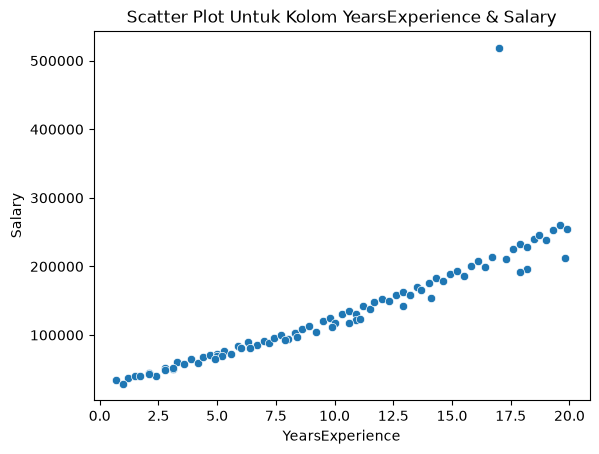

In [81]:
sns.scatterplot(data=df, x='YearsExperience', y='Salary')
plt.title("Scatter Plot Untuk Kolom YearsExperience & Salary")
plt.show()

### 3.5 Pairplot

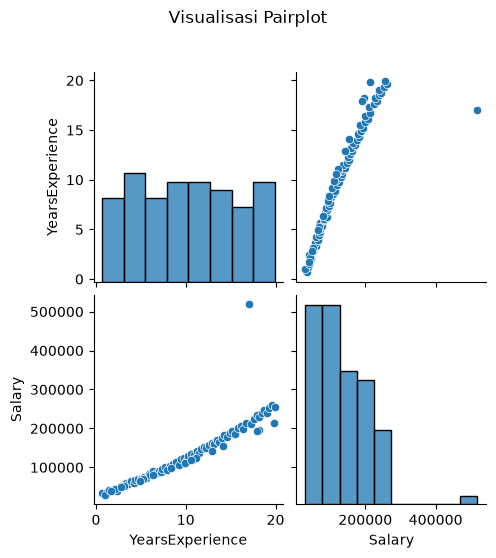

In [82]:
g = sns.pairplot(df, vars=['YearsExperience', 'Salary'])
g.fig.suptitle("Visualisasi Pairplot", y=1.1)
plt.show()

### 3.6 Menganalisis Outlier dengan Boxplot

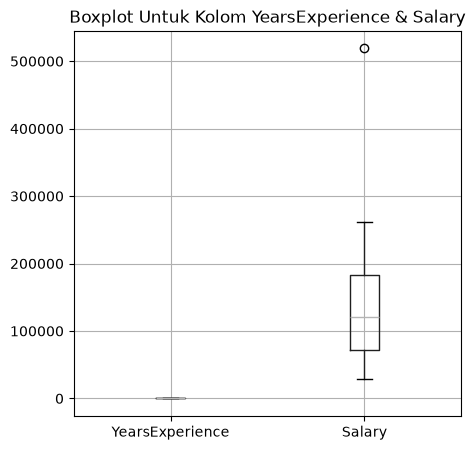

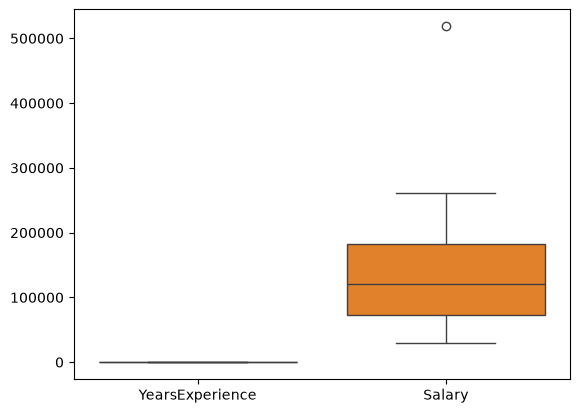

In [83]:
plt.figure(figsize=[5,5])
df.boxplot(column=['YearsExperience', 'Salary'])
plt.title("Boxplot Untuk Kolom YearsExperience & Salary")
plt.show()

sns.boxplot(df)
plt.show()

### 3.7 Analisis Outlier dengan IQR (Interquartile Range)

In [84]:
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((df['Salary'] < batas_bawah) | (df['Salary'] > batas_atas)).sum()
print("Outlier pada kolom Salary berjumlah :", outlier)


Outlier pada kolom Salary berjumlah : 1


### 3.8 Menampilkan Nilai yang Termasuk Outlier

In [85]:
outliers = df[(df['Salary'] < batas_bawah) | (df['Salary'] > batas_atas)]
outliers


,YearsExperience,Salary
59,17.0,518900.0


### 3.9 Analisis Outlier dengan Z-Score

In [86]:
z_score = (df['Salary'] - df['Salary'].mean()) / df['Salary'].std()

outlier = (np.abs(z_score) > 3)

print("Jumlah Outlier Di Kolom Salary :", outlier.sum())
print("-" * 35)

df_outlier = df[outlier]
print(df_outlier)


Jumlah Outlier Di Kolom Salary : 1
-----------------------------------
    YearsExperience    Salary
59             17.0  518900.0


### 3.10 Analisis Korelasi Data

* **Metode Kendall**

In [87]:
corr_kendall = df.corr(method='kendall')
corr_kendall

,YearsExperience,Salary
YearsExperience,1.000000,0.937565
Salary,0.937565,1.000000


* **Metode Spearman**

In [89]:
corr_spearman = df.corr(method='spearman')
corr_spearman

,YearsExperience,Salary
YearsExperience,1.000000,0.992546
Salary,0.992546,1.000000


* **Metode Pearson:**

In [88]:
corr_pearson = df.corr(method='pearson')
corr_pearson


,YearsExperience,Salary
YearsExperience,1.000000,0.891164
Salary,0.891164,1.000000


### 3.11 Visualisasi Heatmap

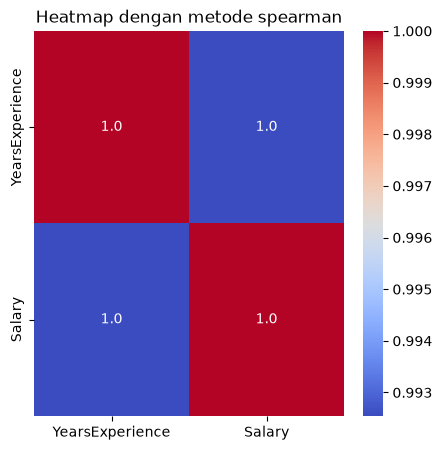

In [90]:
plt.figure(figsize=(5,5))
plt.title('Heatmap dengan metode spearman')
sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', fmt=".1f")
plt.show()


---

## 4. KESIMPULAN HASIL ANALISIS DATA

Kompensasi karyawan naik seiring masa kerja. Data punya tiga masalah yaitu Baris 70 dan 71 kosong, Baris 27-28 dan 45-46 adalah dua pasang duplikat, dan Baris 59 mencatat masa kerja 17 tahun dengan gaji Rp 518.900. Sosusi nya adalah menangani nilai kosong, menghapus baris duplikat, dan menyesuaikan outlier sebelum membangun model regresi agar model tidak bergeser. Manajemen SDM perlu menetapkan rentang gaji yang transparan untuk setiap jenjang masa kerja.